# House Prices — EDA

Exploratory analysis for the [House Prices: Advanced Regression Techniques](https://www.kaggle.com/c/house-prices-advanced-regression-techniques) competition.

**Target:** `SalePrice` — a price in dollars, so this is regression. The leaderboard metric is RMSE on `log1p(SalePrice)` (the log of the price, explained in section 7).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme()

df = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")
target = "SalePrice" 

## 1. First look

In [2]:
df.head(10)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
5,6,50,RL,85.0,14115,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Mitchel,Norm,Norm,1Fam,1.5Fin,5,5,1993,1995,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,Wood,Gd,TA,No,GLQ,732,Unf,0,64,796,GasA,Ex,Y,SBrkr,796,566,0,1362,1,0,1,1,1,1,TA,5,Typ,0,NaN,Attchd,1993.0,Unf,2,480,TA,TA,Y,40,30,0,320,0,0,NaN,MnPrv,Shed,700,10,2009,WD,Normal,143000
6,7,20,RL,75.0,10084,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Somerst,Norm,Norm,1Fam,1Story,8,5,2004,2005,Gable,CompShg,VinylSd,VinylSd,Stone,186.0,Gd,TA,PConc,Ex,TA,Av,GLQ,1369,Unf,0,317,1686,GasA,Ex,Y,SBrkr,1694,0,0,1694,1,0,2,0,3,1,Gd,7,Typ,1,Gd,Attchd,2004.0,RFn,2,636,TA,TA,Y,255,57,0,0,0,0,NaN,NaN,NaN,0,8,2007,WD,Normal,307000
7,8,60,RL,NaN,10382,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NWAmes,PosN,Norm,1Fam,2Story,7,6,1973,1973,Gable,CompShg,HdBoard,HdBoard,Stone,240.0,TA,TA,CBlock,Gd,TA,Mn,ALQ,859,BLQ,32,216,1107,GasA,Ex,Y,SBrkr,1107,983,0,2090,1,0,2,1,3,1,TA,7,Typ,2,TA,Attchd,1973.0,RFn,2,484,TA,TA,Y,235,204,228,0,0,0,NaN,NaN,Shed,350,11,2009,WD,Normal,200000
8,9,50,RM,51.0,6120,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,OldTown,Artery,Norm,1Fam,1.5Fin,7,5,1931,1950,Gable,CompShg,BrkFace,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,TA,No,Unf,0,Unf,0,952,952,GasA,Gd,Y,FuseF,1022,752,0,1774,0,0,2,0,2,2,TA,8,Min1,2,TA,Detchd,1931.0,Unf,2,468,Fa,TA,Y,90,0,205,0,0,0,NaN,NaN,NaN,0,4,2008,WD,Abnorml,129900
9,10,190,RL,50.0,7420,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,BrkSide,Artery,Artery,2fmCon,1.5Unf,5,6,1939,1950,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,BrkTil,TA,TA,No,GLQ,851,Unf,0,140,991,GasA,Ex,

## 2. Basic info

In [3]:
print("Train:", df.shape, "| Test:", test.shape)
df.info()

Train: (1460, 81) | Test: (1459, 80)
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-nu

In [4]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1379.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,567.240411,1057.429452,1162.626712,346.992466,5.844521,1515.463699,0.425342,0.057534,1.565068,0.382877,2.866438,1.046575,6.517808,0.613014,1978.506164,1.767123,472.980137,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,441.866955,438.705324,386.587738,436.528436,48.623081,525.480383,0.518911,0.238753,0.550916,0.502885,0.815778,0.220338,1.625393,0.644666,24.689725,0.747315,213.804841,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,0.000000,0.000000,334.000000,0.000000,0.000000,334.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,1900.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,0.000000,223.000000,795.750000,882.000000,0.000000,0.000000,1129.500000,0.000000,0.000000,1.000000,0.000000,2.000000,1.000000,5.000000,0.000000,1961.000000,1.000000,334.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,0.000000,477.500000,991.500000,1087.000000,0.000000,0.000000,1464.000000,0.000000,0.000000,2.000000,0.000000,3.000000,1.000000,6.000000,1.000000,1980.000000,2.000000,480.000000,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,0.000000,808.000000,1298.250000,1391.250000,728.000000,0.000000,1776.750000,1.000000,0.000000,2.000000,1.000000,3.000000,1.000000,7.000000,1.000000,2002.000000,2.000000,576.000000,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1474.000000,2336.000000,6110.000000,4692.000000,2065.000000,572.000000,5642.000000,3.000000,2.000000,3.000000,2.000000,8.000000,3.000000,14.000000,3.000000,2010.000000,4.000000,1418.000000,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


1460 houses, 80 features. The columns by role:

| Role | Columns |
|---|---|
| ID | Id |
| Target | SalePrice |
| Numbers | 36 columns — areas, counts, years (LotArea, GrLivArea, YearBuilt, ...) |
| Categories | 43 columns — zoning, neighborhood, quality grades, types |
| Text | none — every string is one of a fixed set of labels |

Two things to fix before encoding:
- **MSSubClass** looks numeric but is really a category (a building-type code).
- Many categories are quality grades with a natural order (`Po < Fa < TA < Gd < Ex`), e.g. ExterQual, KitchenQual, BsmtQual. These should become ordered numbers, not one-hot.

## 3. Duplicates

In [5]:
print("full rows:", df.duplicated().sum())
print("ignoring Id:", df.drop(columns="Id").duplicated().sum())

full rows: 0
ignoring Id: 0


No duplicates, nothing to drop.

## 4. Unique values

In [6]:
df.nunique().sort_values()

CentralAir         2
Utilities          2
Street             2
Alley              2
BsmtHalfBath       3
                ... 
1stFlrSF         753
BsmtUnfSF        780
GrLivArea        861
LotArea         1073
Id              1460
Length: 81, dtype: int64

- No constant columns (nothing to drop).
- Most categories have only a handful of values — easy to encode.
- The biggest is Neighborhood (25). Still a fixed list, not free text, so there's nothing to parse — the whole dataset is plain tables.

## 5. Correlation & leakage

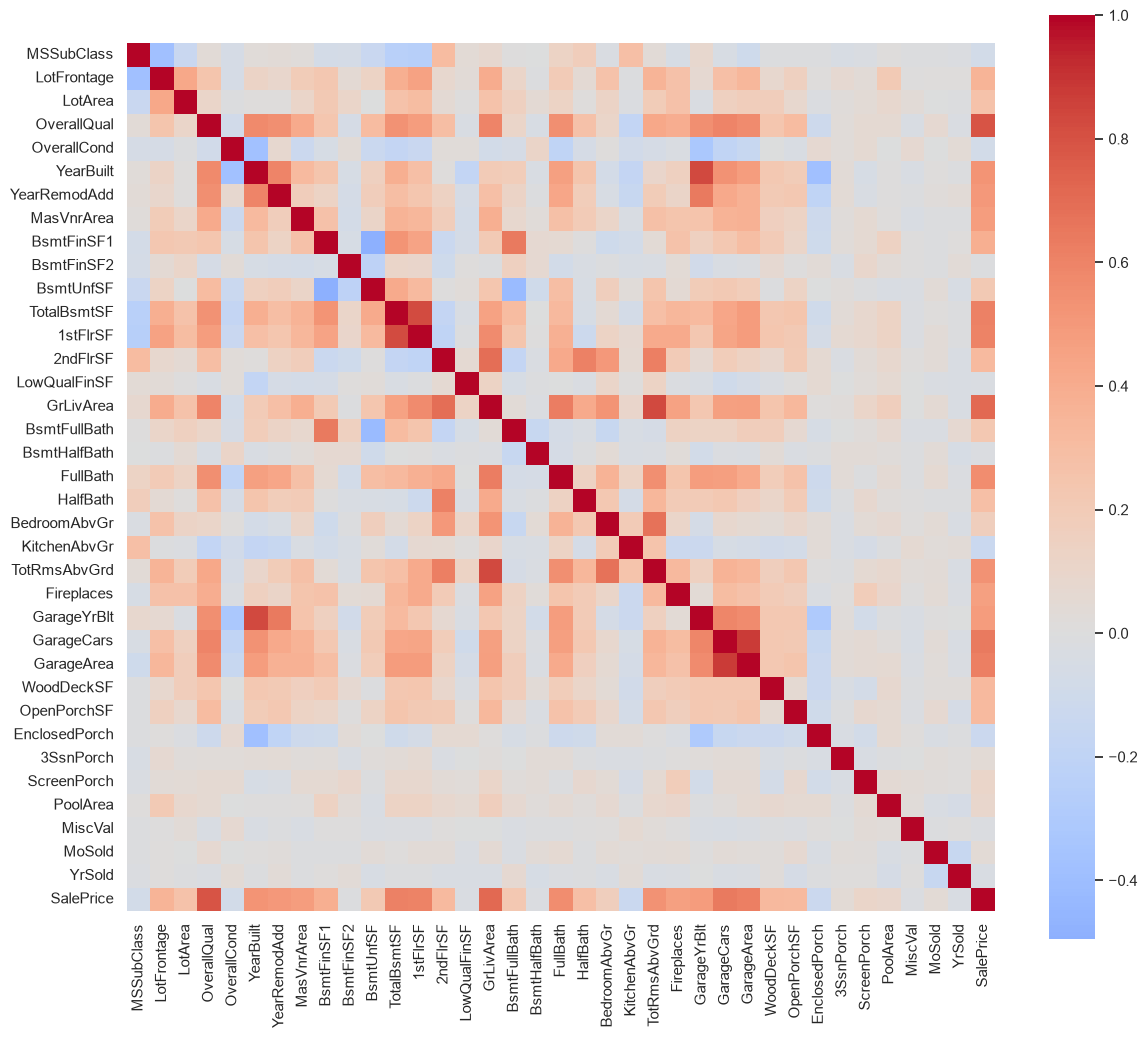

In [7]:
num_df = df.select_dtypes("number").drop(columns="Id")
corr = num_df.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True,
            xticklabels=True, yticklabels=True)
plt.show()

In [8]:
# pairs of features that are almost the same thing
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().sort_values(ascending=False)
pairs[pairs.abs() > 0.8]

GarageCars   GarageArea      0.882475
YearBuilt    GarageYrBlt     0.825667
GrLivArea    TotRmsAbvGrd    0.825489
TotalBsmtSF  1stFlrSF        0.819530
dtype: float64

What the heatmap shows:

- No pair of features is correlated close to 1, so nothing is a duplicate to drop. The closest are GarageCars–GarageArea (0.88) and YearBuilt–GarageYrBlt (0.83) — related, but not the same.
- The features most linked to the price are OverallQual (0.79), GrLivArea (living area, 0.71), and the garage size.

Now **leakage** = the model seeing information during training that it won't have for a new house (e.g. something recorded after the sale). Two checks: do train and test share rows, and does any single feature predict the price suspiciously well.

In [9]:
print("Id overlap:", len(set(df["Id"]) & set(test["Id"])))
print("train Id range:", df["Id"].min(), "-", df["Id"].max())
print("test  Id range:", test["Id"].min(), "-", test["Id"].max())

Id overlap: 0
train Id range: 1 - 1460
test  Id range: 1461 - 2919


In [10]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

y = np.log1p(df[target])

def single_feature_r2(col):
    """How well one column alone predicts the price (R2: 1 = perfect, 0 = useless)."""
    pipe = Pipeline([
        ("fill", ColumnTransformer([("f", SimpleImputer(strategy="median"), [col])])),
        ("rf", RandomForestRegressor(n_estimators=100, random_state=42)),
    ])
    return cross_val_score(pipe, df[[col]], y, cv=5, scoring="r2").mean()

for col in ["OverallQual", "GrLivArea", "GarageCars", "YearBuilt", "Id"]:
    print(f"{col:12s} R2 = {single_feature_r2(col):.3f}")

OverallQual  R2 = 0.669


GrLivArea    R2 = 0.373
GarageCars   R2 = 0.482


YearBuilt    R2 = 0.391


Id           R2 = -0.435


- Train and test don't overlap (train is Ids 1–1460, test 1461–2919). Id is just a row counter.
- The best single feature is OverallQual at R² 0.67 — strong but believable. If something scored ~0.99 it would mean it secretly contains the price. Nothing does.
- Id scores below 0 (worse than guessing the average), so row order means nothing.

No leakage: every column is a property feature known at sale time, none is built from the price.

## 6. NaNs

In [11]:
na = df.isna().sum()
na = na[na > 0].sort_values(ascending=False)
pd.DataFrame({"n_missing": na, "pct": (na / len(df) * 100).round(1)})

,n_missing,pct
PoolQC,1453,99.5
MiscFeature,1406,96.3
Alley,1369,93.8
Fence,1179,80.8
MasVnrType,872,59.7
FireplaceQu,690,47.3
LotFrontage,259,17.7
GarageType,81,5.5
GarageYrBlt,81,5.5
GarageFinish,81,5.5


Most "missing" values here aren't really missing — `NA` means the house doesn't have that thing (PoolQC = NA means no pool). So they're filled with a real value, not guessed (done inside the pipeline, so it repeats on every CV fold):

- **"None" / 0** for the "feature absent" columns: PoolQC, Alley, Fence, the basement and garage columns, etc.
- Only **LotFrontage** (259 missing) is truly unknown → filled with the median for that Neighborhood. **Electrical** (1) → most common value.

## 7. Target analysis

In [12]:
df[target].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

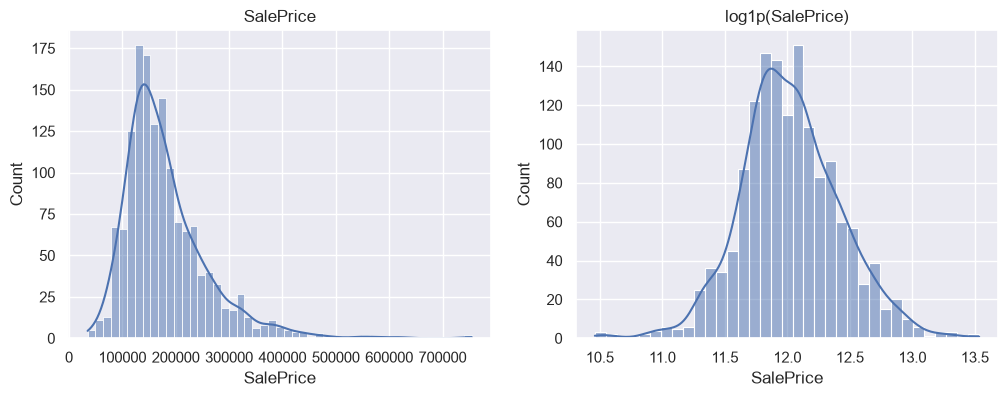

skew: 1.88 | after log: 0.12


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[target], kde=True, ax=axes[0])
axes[0].set_title("SalePrice")
sns.histplot(np.log1p(df[target]), kde=True, ax=axes[1])
axes[1].set_title("log1p(SalePrice)")
plt.show()

print("skew:", df[target].skew().round(2), "| after log:", np.log1p(df[target]).skew().round(2))

Prices are skewed right — most houses are cheap, a few are very expensive (skew 1.88). Taking the log makes the shape symmetric (skew 0.12), which models handle better. That's why the competition scores `log1p(SalePrice)` and why we train on it.

The bar to beat: always guessing the average price gives an RMSE of about 0.40 on the log scale. Every real model (section 12) beats that easily.

## 8. Feature distributions

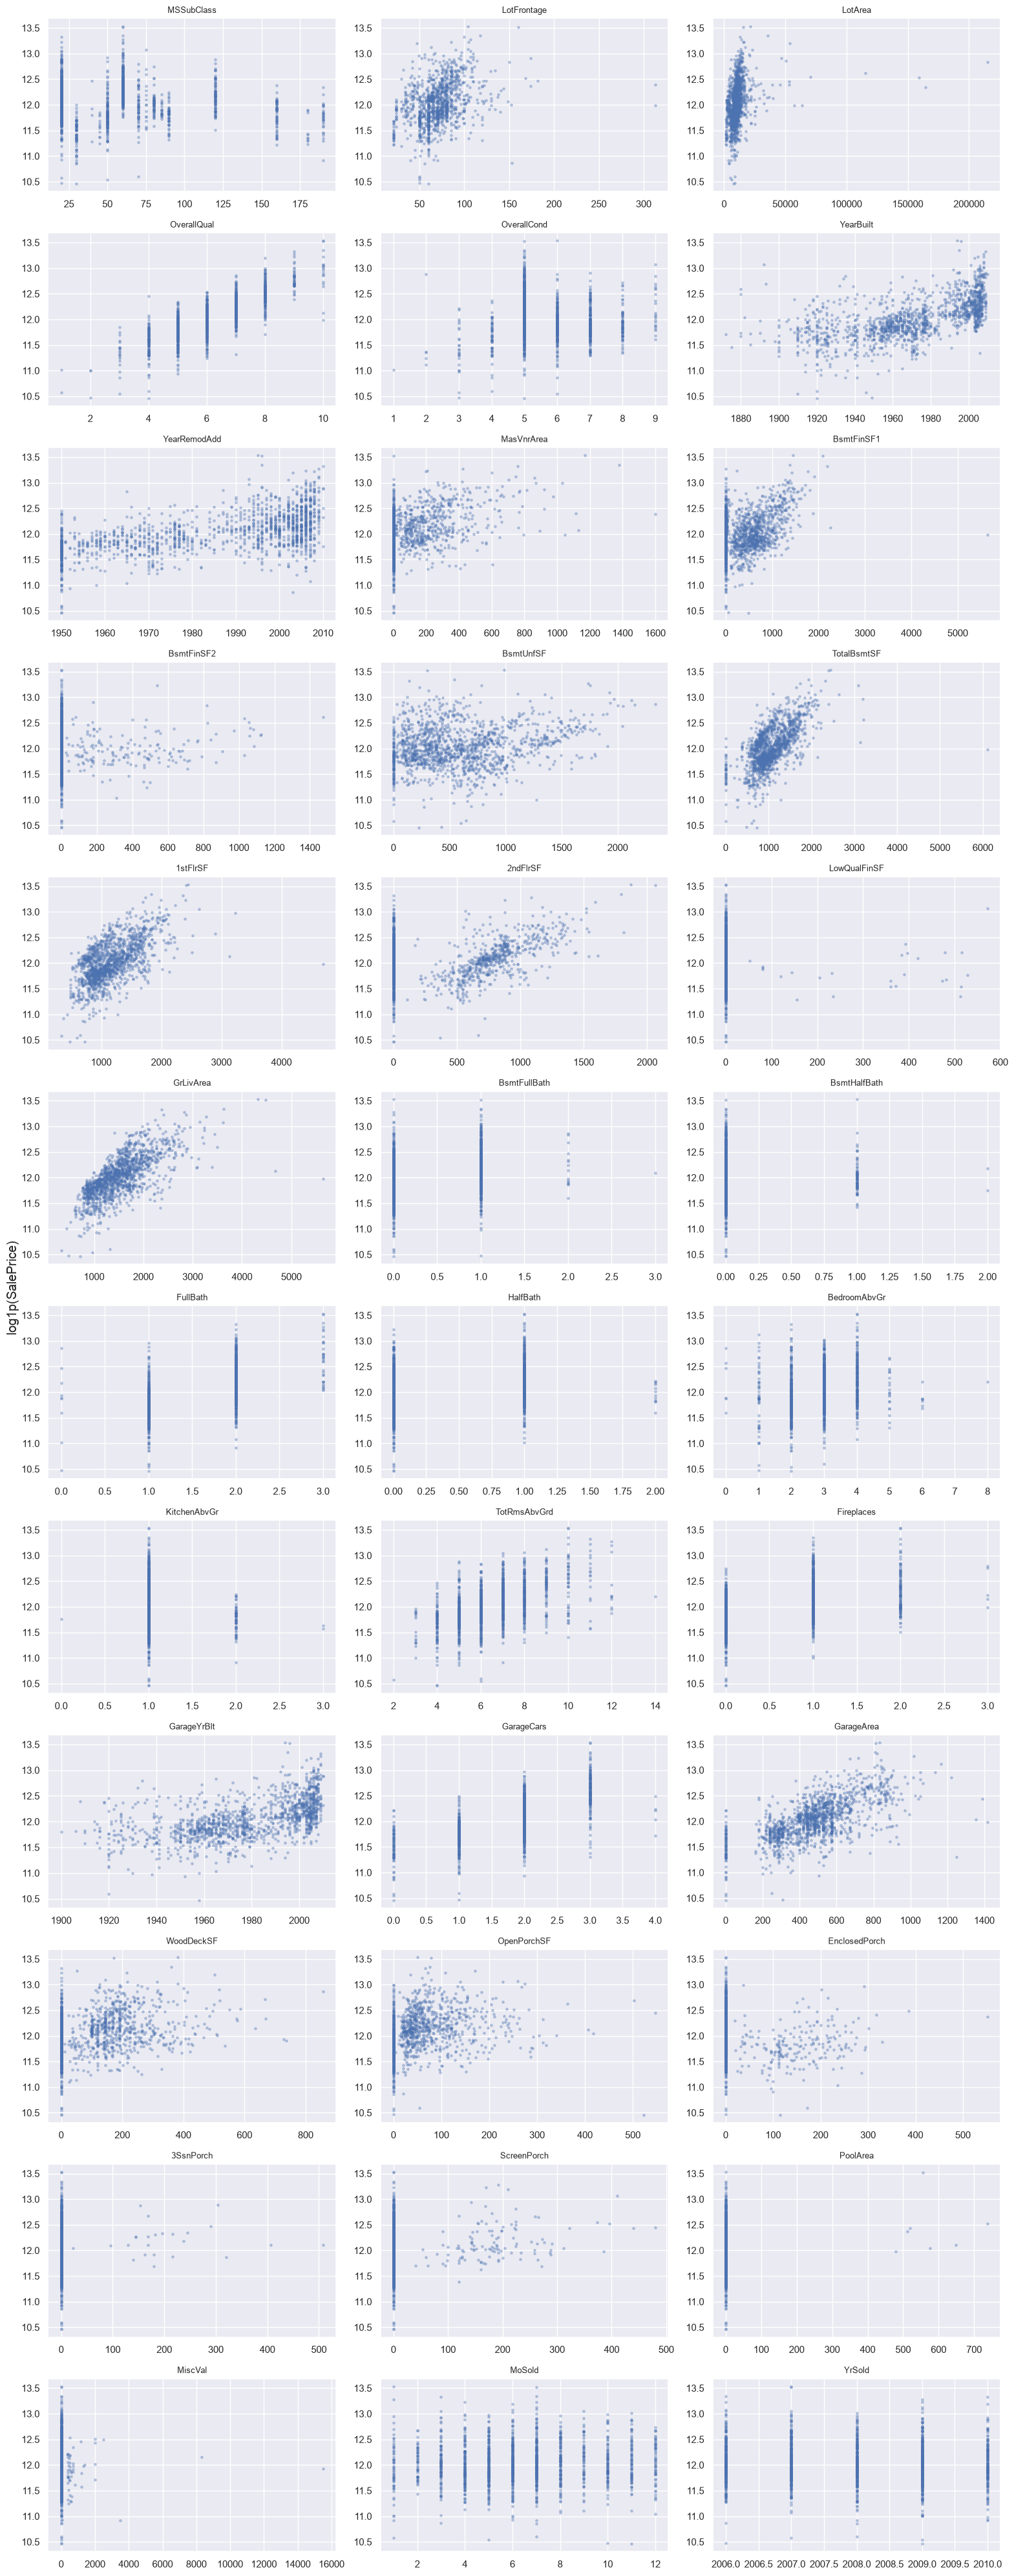

In [14]:
ylog = np.log1p(df[target])
num_cols = num_df.columns.drop(target)

fig, axes = plt.subplots(12, 3, figsize=(16, 40))
for ax, col in zip(axes.flat, num_cols):
    ax.scatter(df[col], ylog, s=6, alpha=0.3)
    ax.set_title(col, fontsize=9)
for ax in axes.flat[len(num_cols):]:
    ax.axis("off")
fig.supylabel("log1p(SalePrice)")
plt.tight_layout()
plt.show()

In [15]:
df[num_df.columns.drop(target)].skew().sort_values(ascending=False).head(10)

MiscVal          24.476794
PoolArea         14.828374
LotArea          12.207688
3SsnPorch        10.304342
LowQualFinSF      9.011341
KitchenAbvGr      4.488397
BsmtFinSF2        4.255261
ScreenPorch       4.122214
BsmtHalfBath      4.103403
EnclosedPorch     3.089872
dtype: float64

Each dot is a house: the feature on x, log-price on y. Dots instead of histograms so the zero-heavy columns still read — ScreenPorch, PoolArea, 3SsnPorch show up as a vertical stripe at x=0, because most houses simply don't have that feature (a histogram just collapses them into one bar).

- Clear upward trends: GrLivArea, GarageArea, TotalBsmtSF, OverallQual, the year columns.
- Many features are very skewed (ranking above) — a few huge values. The pipeline scales them, and trees/boosting don't mind skew.

Zooming in on living area, the single strongest area feature:

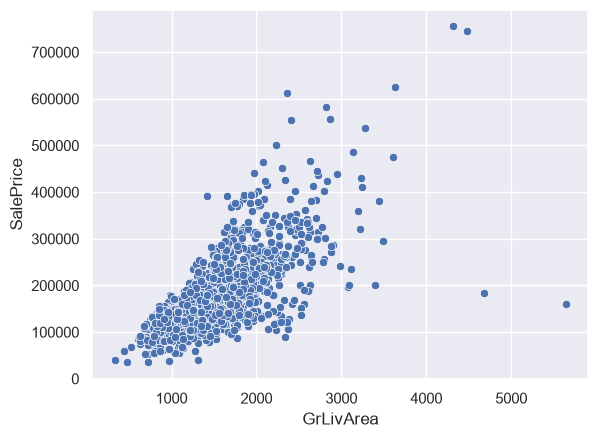

In [16]:
sns.scatterplot(data=df, x="GrLivArea", y=target)
plt.show()

The trend is clearly upward, except two huge houses that sold cheap (bottom right) — likely partial/odd sales. They're kept for now; boosting handles them well, and dropping them barely moves the score.

## 9. Categorical features

In [17]:
cat_cols = df.select_dtypes(exclude="number").columns
df[cat_cols].nunique().sort_values(ascending=False)

Neighborhood     25
Exterior2nd      16
Exterior1st      15
SaleType          9
Condition1        9
Condition2        8
HouseStyle        8
RoofMatl          8
Functional        7
BsmtFinType2      6
Heating           6
RoofStyle         6
SaleCondition     6
BsmtFinType1      6
GarageType        6
Foundation        6
Electrical        5
FireplaceQu       5
HeatingQC         5
GarageQual        5
GarageCond        5
MSZoning          5
LotConfig         5
ExterCond         5
BldgType          5
BsmtExposure      4
MiscFeature       4
Fence             4
LotShape          4
LandContour       4
BsmtCond          4
KitchenQual       4
ExterQual         4
BsmtQual          4
LandSlope         3
GarageFinish      3
MasVnrType        3
PavedDrive        3
PoolQC            3
Utilities         2
CentralAir        2
Street            2
Alley             2
dtype: int64

Two kinds, encoded differently (in `src/features.py`):

- **Ordered grades → numbers 0–5** (Po/Fa/TA/Gd/Ex): ExterQual, KitchenQual, BsmtQual, HeatingQC, the garage/pool quality columns, etc.
- **Everything else → one-hot**: Neighborhood, MSZoning, types... MSSubClass goes here too (turned into a string first, since its numbers are just codes).

## 10. Optimization

In [18]:
print(f"{df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

3.6 MB


Under 4 MB — memory isn't an issue at this size. Nothing to optimize.

## 11. Multimodal preprocessing

Nothing to do — no images, audio or free text. Every column is already a number or a fixed category.

## 12. Key takeaways

All models compared with 5-fold **stratified** CV (folds balanced on binned price) — RMSE on `log1p(SalePrice)`, lower is better, seed 42. **linreg is the baseline.** Reproduce with `uv run python compare.py`.

| model | CV RMSE | ± |
|---|---|---|
| catboost | 0.1234 | 0.0208 |
| voting | 0.1334 | 0.0285 |
| stacking_ridge | 0.1345 | 0.0309 |
| lightgbm | 0.1365 | 0.0236 |
| stacking_linreg | 0.1368 | 0.0364 |
| xgboost | 0.1383 | 0.0250 |
| random_forest | 0.1444 | 0.0235 |
| mlp | 0.1459 | 0.0409 |
| ridge | 0.1572 | 0.0450 |
| lasso | 0.1597 | 0.0485 |
| elasticnet | 0.1605 | 0.0504 |
| knn | 0.1684 | 0.0108 |
| linreg (baseline) | 0.1822 | 0.0474 |
| decision_tree | 0.1933 | 0.0155 |

- **Boosting wins** — catboost is best at 0.1234, ~32% better than the linreg baseline.
- **Ensembles** (voting / stacking of ridge + rf + lgbm) land just behind catboost — combining models helps, but doesn't beat the best single booster here.
- Linear models and the MLP are mid-pack; a single tree and KNN are weakest.

**The pipeline** (`src/features.py`, `src/pipeline.py`): fill NaNs by meaning → encode ordered grades as 0–5 and the rest one-hot → add a few engineered features (TotalSF, TotalBath, HouseAge, Has-pool/garage/etc. flags) → train on `log1p(SalePrice)`. Everything is fit inside the pipeline, so each CV fold learns its own statistics.